MODELO DE LA LÍNEA 3 DEL METRO CDMX CON NETWORKX
-------------------------------------------------
Qué hace este programa:
- Representa la Línea 3 (Indios Verdes - Universidad) como un grafo.
- Cada ESTACIÓN es un NODO.
- Cada conexión entre estaciones vecinas es una ARISTA.
- Después consulta datos del grafo, busca una ruta y dibuja la línea.

#$Importaciones$

`networkx as nx`: la librería que crea y analiza grafos.

`matplotlib.pyplot as plt`: la librería que dibuja las gráficas.

Graph named 'Línea 3 del Metro CDMX' with 21 nodes and 20 edges
Número de estaciones: 21
Número de conexiones: 20

Estaciones con transbordo:
  Deportivo 18 de Marzo: Línea(s) 6
  La Raza: Línea(s) 5
  Guerrero: Línea(s) B
  Hidalgo: Línea(s) 2
  Balderas: Línea(s) 1
  Centro Médico: Línea(s) 9
  Zapata: Línea(s) 12


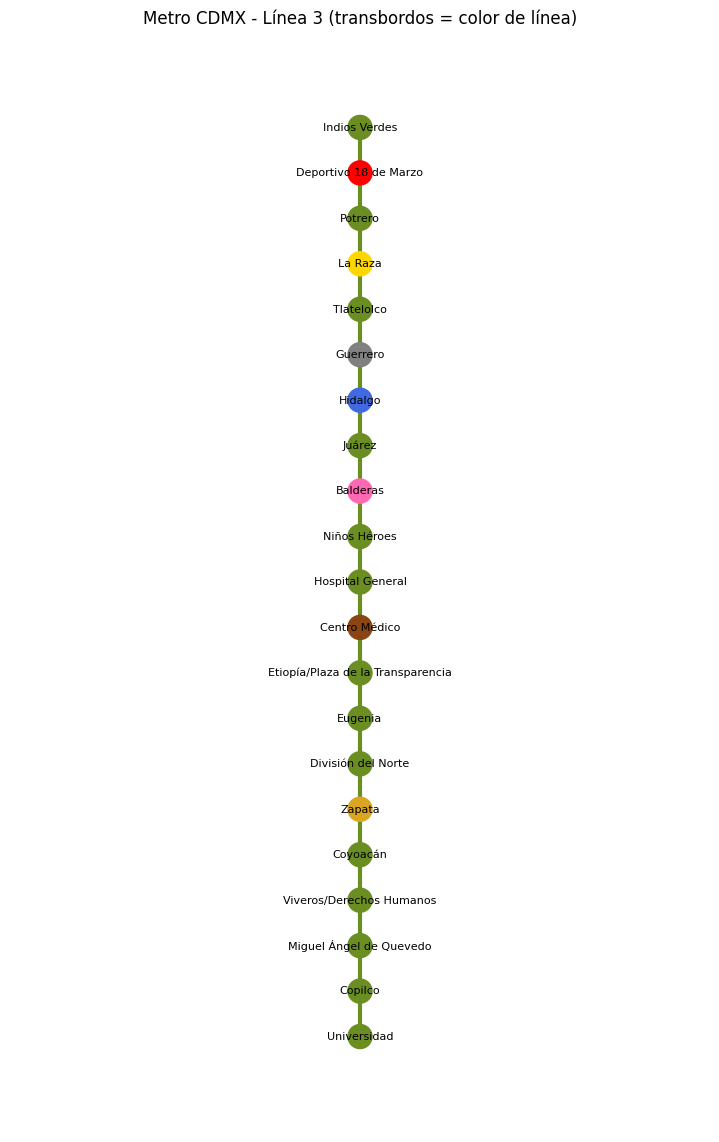

In [22]:
import networkx as nx
import matplotlib.pyplot as plt
"""
PASO 1: DATOS
'estaciones' es una LISTA con los nombres en orden de norte a sur.
El orden importa porque más abajo conectamos cada estación con la siguiente.
"""
estaciones = [
    "Indios Verdes",
    "Deportivo 18 de Marzo",
    "Potrero",
    "La Raza",
    "Tlatelolco",
    "Guerrero",
    "Hidalgo",
    "Juárez",
    "Balderas",
    "Niños Héroes",
    "Hospital General",
    "Centro Médico",
    "Etiopía/Plaza de la Transparencia",
    "Eugenia",
    "División del Norte",
    "Zapata",
    "Coyoacán",
    "Viveros/Derechos Humanos",
    "Miguel Ángel de Quevedo",
    "Copilco",
    "Universidad",
]

"""
'transbordos' es un DICCIONARIO:
- La clave es el nombre de la estación.
- El valor es la lista de líneas a las que se puede cambiar ahí.
Las estaciones que no aparecen aquí no tienen transbordo.
"""
transbordos = {
    "Deportivo 18 de Marzo": ["6"],
    "La Raza": ["5"],
    "Guerrero": ["B"],
    "Hidalgo": ["2"],
    "Balderas": ["1"],
    "Centro Médico": ["9"],
    "Zapata": ["12"],
}

"""
'colores_lineas' asocia el identificador de cada línea con su color en
matplotlib para pintar los nodos de transbordo según la línea de conexión.
"""
colores_lineas = {
    "1": "hotpink",
    "2": "royalblue",
    "3": "olivedrab",
    "4": "turquoise",
    "5": "gold",
    "6": "red",
    "7": "darkorange",
    "8": "forestgreen",
    "9": "saddlebrown",
    "A": "purple",
    "B": "gray",
    "12": "goldenrod",
}


"""
PASO 2: CREAR EL GRAFO
1. nx.Graph() crea un grafo NO DIRIGIDO vacío (se puede viajar en ambos
sentidos, como en el metro).
2. 'name' solo le pone un nombre al grafo.
3. La variable G guarda el grafo para usarlo después.
"""
G = nx.Graph(name="Línea 3 del Metro CDMX")

"""
PASO 3: AGREGAR LOS NODOS
- enumerate(estaciones, start=1) devuelve parejas (número, nombre):
  (1, "Indios Verdes"), (2, "Deportivo 18 de Marzo"), ...

- G.add_node(nombre, ...) agrega la estación como nodo. Lo que va
  después del nombre son ATRIBUTOS (datos extra guardados en el nodo):
    linea       -> número de la línea (3)
    orden       -> posición de la estación en la línea
    transbordo  -> lista de líneas con las que conecta

- transbordos.get(nombre, []) busca la estación en el diccionario;
  si no está, devuelve una lista vacía [] (sin transbordo).
"""

for numero, nombre in enumerate(estaciones, start=1):
    G.add_node(
        nombre,
        linea=3,
        orden=numero,
        transbordo=transbordos.get(nombre, []),
    )

"""
PASO 4: AGREGAR LAS ARISTAS
- estaciones[1:] es la misma lista pero sin la primera estación.

- zip(estaciones, estaciones[1:]) forma parejas de estaciones vecinas:
  (Indios Verdes, Deportivo 18 de Marzo), (Deportivo 18 de Marzo, Potrero)...

- G.add_edge(origen, destino, weight=1) conecta las dos estaciones.
  'weight' es el PESO (costo) de la conexión. Usamos 1 = una parada.
"""
for origen, destino in zip(estaciones, estaciones[1:]):
    G.add_edge(origen, destino, weight=1)

"""
PASO 5: CONSULTAR INFORMACIÓN DEL GRAFO
- print(G)                    -> resumen (nombre, nodos y aristas).
- G.number_of_nodes()         -> cuántas estaciones hay (21).
- G.number_of_edges()         -> cuántas conexiones hay (20).
"""
print(G)
print("Número de estaciones:", G.number_of_nodes())
print("Número de conexiones:", G.number_of_edges())

"""
MOSTRAR LAS ESTACIONES CON TRANSBORDO
- G.nodes(data=True) recorre cada nodo junto con su diccionario de
  atributos (aquí llamado 'datos').
- 'if datos["transbordo"]' es verdadero solo si la lista NO está vacía.
- ', '.join(...) une los elementos de la lista con comas para imprimirlos.
"""
print("\nEstaciones con transbordo:")
for nombre, datos in G.nodes(data=True):
    if datos["transbordo"]:
        print(f"  {nombre}: Línea(s) {', '.join(datos['transbordo'])}")


"""
PASO 6: DIBUJAR EL GRAFO
"""
posiciones = {nombre: (0, -i) for i, nombre in enumerate(estaciones)}
"""
- 'posiciones' es un diccionario con las coordenadas (x, y) de cada nodo.
-  Con x = 0 y y = -i las estaciones quedan en una línea vertical, de norte (arriba) a sur (abajo).
"""

# Cada transbordo toma el color de la línea con la que conecta (primer elemento)
colores = [
    #- 'colores' es una lista con un color por nodo: si tiene transbordo
    colores_lineas.get(G.nodes[n]["transbordo"][0], "olivedrab")
    if G.nodes[n]["transbordo"] else "olivedrab"
    for n in G.nodes
]
"""
Toma el color de la primera línea de correspondencia en 'colores_lineas';
si no tiene transbordo, usa 'olivedrab' (color de la Línea 3).
"""

#- plt.figure(figsize=(7, 11)) crea un lienzo alto para que quepa los nombres.
plt.figure(figsize=(7, 11))
nx.draw(
    G,
    posiciones,
    with_labels=True,
    node_color=colores,
    node_size=300,
    font_size=8,
    edge_color="olivedrab",
    width=3,
)
"""
  - nx.draw(...) dibuja el grafo:
    `with_labels=True` -> muestra el nombre de cada estación
    `node_color`       -> color de los nodos
    `node_size`        -> tamaño de los nodos
    `edge_color/width` -> color y grosor de las conexiones
"""
plt.title("Metro CDMX - Línea 3 (transbordos = color de línea)")
plt.savefig("linea3.png", dpi=150, bbox_inches="tight")
plt.show()

#Modelo de la red del Metro de la CDMX con $NetworkX$

Idea general:
- Cada ESTACIÓN es un NODO del grafo.
- Cada conexión entre dos estaciones seguidas es una ARISTA.
- El grafo es NO DIRIGIDO, porque en el metro se puede viajar en los dos sentidos.
- Si una estación está en varias líneas (por ejemplo Balderas, que es de la 1
  y de la 3), es UN SOLO nodo. Así los transbordos salen solos: la estación
  conecta con los vecinos de las dos líneas.

Qué se hace en el programa:
1. Guardar las estaciones de las 12 líneas.
2. Construir el grafo.
3. Consultar datos (nodos, aristas, grados, transbordos).
4. Dibujar la red.
"""

Graph named 'Red del Metro CDMX' with 163 nodes and 183 edges
Número de estaciones (nodos): 163
Número de conexiones (aristas): 183

Estaciones de transbordo: 28
  Atlalilco: líneas 8, 12
  Balderas: líneas 1, 3
  Bellas Artes: líneas 2, 8
  Candelaria: líneas 1, 4
  Centro Médico: líneas 3, 9
  Chabacano: líneas 2, 8, 9
  Consulado: líneas 4, 5
  Deportivo 18 de Marzo: líneas 3, 6
  El Rosario: líneas 6, 7
  Ermita: líneas 2, 12
  Garibaldi/Lagunilla: líneas 8, B
  Guerrero: líneas 3, B
  Hidalgo: líneas 2, 3
  Instituto del Petróleo: líneas 5, 6
  Jamaica: líneas 4, 9
  La Raza: líneas 3, 5
  Martín Carrera: líneas 4, 6
  Mixcoac: líneas 7, 12
  Morelos: líneas 4, B
  Oceanía: líneas 5, B
  Pantitlán: líneas 1, 5, 9, A
  Pino Suárez: líneas 1, 2
  Salto del Agua: líneas 1, 8
  San Lázaro: líneas 1, B
  Santa Anita: líneas 4, 8
  Tacuba: líneas 2, 7
  Tacubaya: líneas 1, 7, 9
  Zapata: líneas 3, 12

Las 5 estaciones con más conexiones directas:
  Chabacano: grado 6
  Tacubaya: grado 5

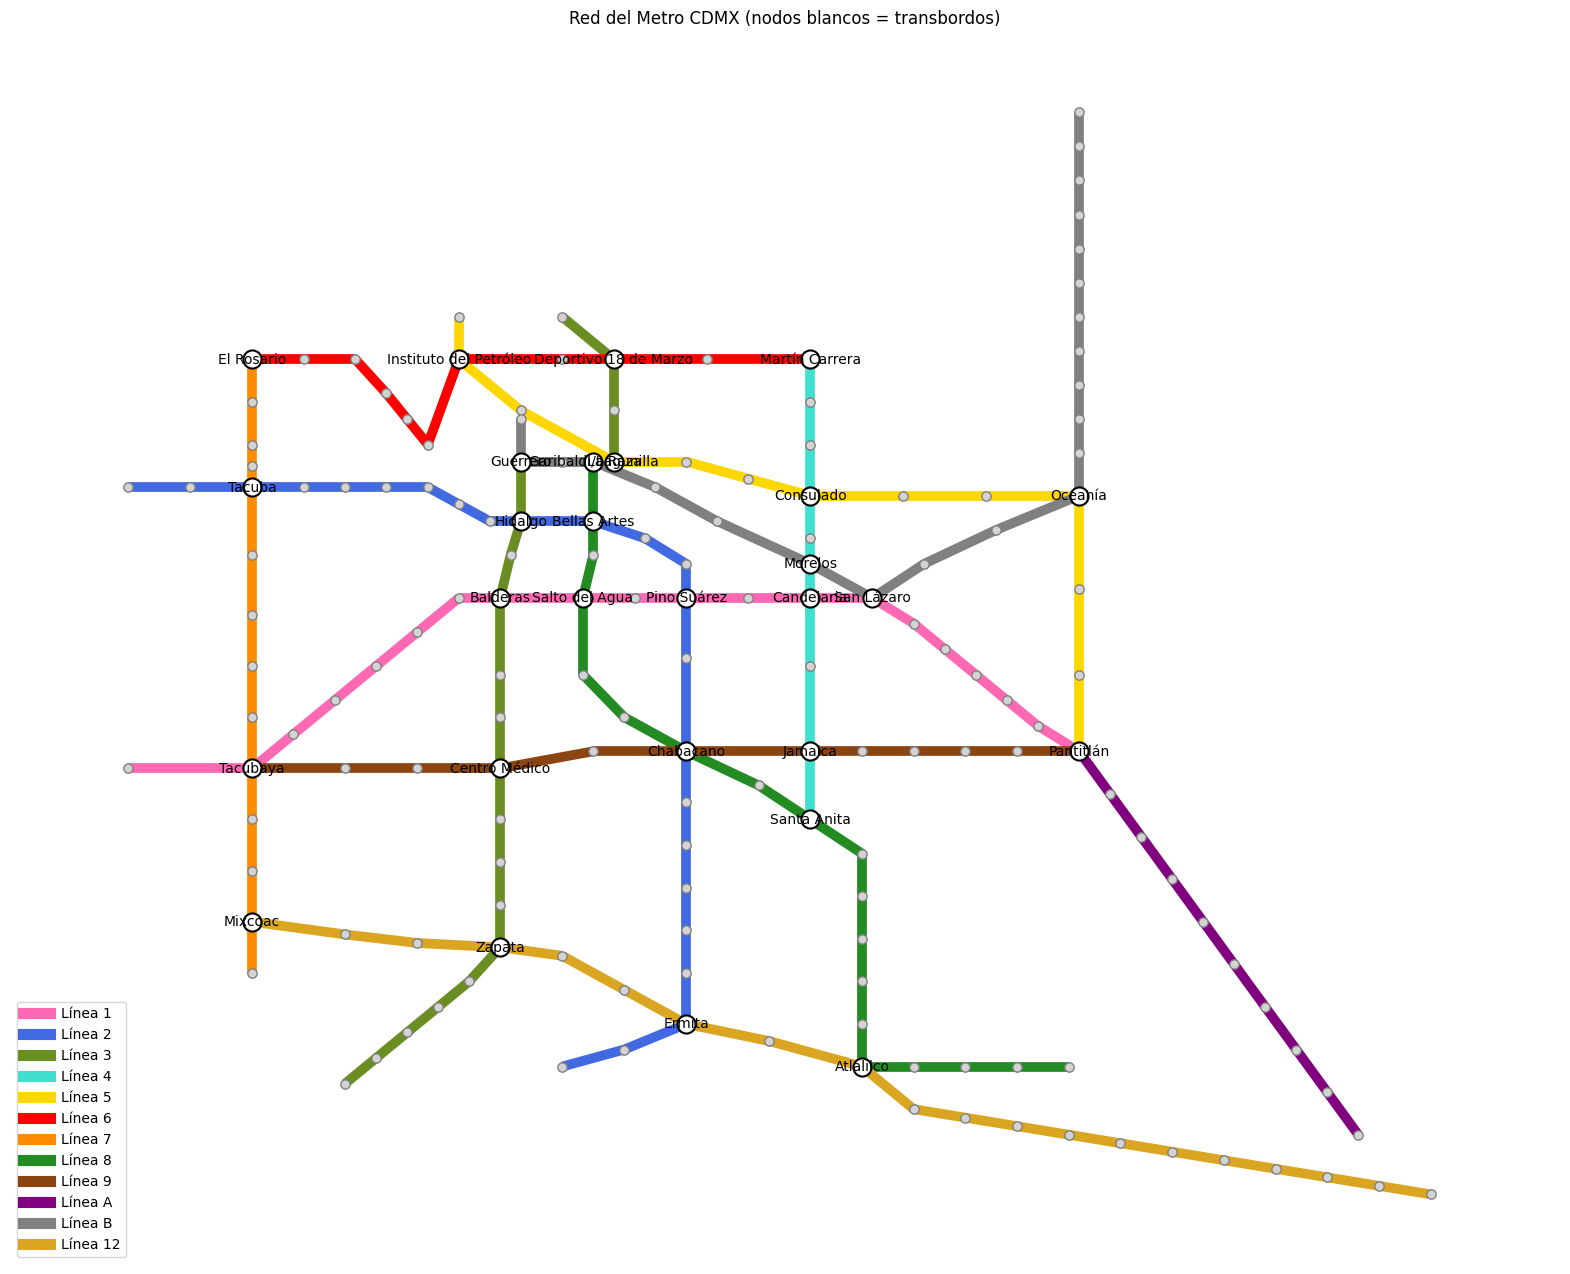

In [23]:
import networkx as nx
import matplotlib.pyplot as plt


# ---------------------------------------------------------------
# 1. DATOS
# ---------------------------------------------------------------
"""
Esta sección define las estructuras base de datos para el programa:
- 'lineas': diccionario con cada línea del Metro y sus estaciones en orden
  (normalmente va antes de 'coords' en el script completo).
- 'coords': diccionario que asigna una posición (x, y) a cada estación
  para dibujar la red con una forma parecida al mapa del Metro.
"""
"""
# Diccionario: la clave es el nombre de la línea y el valor es la lista de
sus estaciones EN ORDEN. El orden importa, porque después conecto cada
estación con la siguiente de la lista.

Los nombres de las estaciones con transbordo tienen que estar escritos
EXACTAMENTE igual en todas las líneas. Si no, Python las toma como
estaciones distintas.

# Diccionario de coordenadas:
# - Clave (str): nombre exacto de la estación (debe coincidir con 'lineas').
# - Valor (tuple de floats): (x, y), donde 'x' controla la posición horizontal
#   (izquierda/derecha) y 'y' la posición vertical (abajo/arriba) en la gráfica.
"""
lineas = {
    "1": [
        "Observatorio", "Tacubaya", "Juanacatlán", "Chapultepec", "Sevilla",
        "Insurgentes", "Cuauhtémoc", "Balderas", "Salto del Agua",
        "Isabel la Católica", "Pino Suárez", "Merced", "Candelaria",
        "San Lázaro", "Moctezuma", "Balbuena", "Boulevard Puerto Aéreo",
        "Gómez Farías", "Zaragoza", "Pantitlán",
    ],
    "2": [
        "Cuatro Caminos", "Panteones", "Tacuba", "Cuitláhuac", "Popotla",
        "Colegio Militar", "Normal", "San Cosme", "Revolución", "Hidalgo",
        "Bellas Artes", "Allende", "Zócalo/Tenochtitlan", "Pino Suárez",
        "San Antonio Abad", "Chabacano", "Viaducto", "Xola",
        "Villa de Cortés", "Nativitas", "Portales", "Ermita",
        "General Anaya", "Tasqueña",
    ],
    "3": [
        "Indios Verdes", "Deportivo 18 de Marzo", "Potrero", "La Raza",
        "Tlatelolco", "Guerrero", "Hidalgo", "Juárez", "Balderas",
        "Niños Héroes", "Hospital General", "Centro Médico",
        "Etiopía/Plaza de la Transparencia", "Eugenia", "División del Norte",
        "Zapata", "Coyoacán", "Viveros/Derechos Humanos",
        "Miguel Ángel de Quevedo", "Copilco", "Universidad",
    ],
    "4": [
        "Martín Carrera", "Talismán", "Bondojito", "Consulado",
        "Canal del Norte", "Morelos", "Candelaria", "Fray Servando",
        "Jamaica", "Santa Anita",
    ],
    "5": [
        "Politécnico", "Instituto del Petróleo", "Autobuses del Norte",
        "La Raza", "Misterios", "Valle Gómez", "Consulado", "Eduardo Molina",
        "Aragón", "Oceanía", "Terminal Aérea", "Hangares", "Pantitlán",
    ],
    "6": [
        "El Rosario", "Tezozómoc", "UAM-Azcapotzalco",
        "Ferrería/Arena Ciudad de México", "Norte 45", "Vallejo",
        "Instituto del Petróleo", "Lindavista", "Deportivo 18 de Marzo",
        "La Villa-Basílica", "Martín Carrera",
    ],
    "7": [
        "El Rosario", "Aquiles Serdán", "Camarones", "Refinería", "Tacuba",
        "San Joaquín", "Polanco", "Auditorio", "Constituyentes", "Tacubaya",
        "San Pedro de los Pinos", "San Antonio", "Mixcoac",
        "Barranca del Muerto",
    ],
    "8": [
        "Garibaldi/Lagunilla", "Bellas Artes", "San Juan de Letrán",
        "Salto del Agua", "Doctores", "Obrera", "Chabacano", "La Viga",
        "Santa Anita", "Coyuya", "Iztacalco", "Apatlaco", "Aculco",
        "Escuadrón 201", "Atlalilco", "Iztapalapa", "Cerro de la Estrella",
        "UAM-I", "Constitución de 1917",
    ],
    "9": [
        "Tacubaya", "Patriotismo", "Chilpancingo", "Centro Médico",
        "Lázaro Cárdenas", "Chabacano", "Jamaica", "Mixiuhca", "Velódromo",
        "Ciudad Deportiva", "Puebla", "Pantitlán",
    ],
    "A": [
        "Pantitlán", "Agrícola Oriental", "Canal de San Juan", "Tepalcates",
        "Guelatao", "Peñón Viejo", "Acatitla", "Santa Marta", "Los Reyes",
        "La Paz",
    ],
    "B": [
        "Buenavista", "Guerrero", "Garibaldi/Lagunilla", "Lagunilla",
        "Tepito", "Morelos", "San Lázaro", "Ricardo Flores Magón",
        "Romero Rubio", "Oceanía", "Deportivo Oceanía", "Bosque de Aragón",
        "Villa de Aragón", "Nezahualcóyotl", "Impulsora",
        "Río de los Remedios", "Múzquiz", "Ecatepec", "Olímpica",
        "Plaza Aragón", "Ciudad Azteca",
    ],
    "12": [
        "Mixcoac", "Insurgentes Sur", "Hospital 20 de Noviembre", "Zapata",
        "Parque de los Venados", "Eje Central", "Ermita", "Mexicaltzingo",
        "Atlalilco", "Culhuacán", "San Andrés Tomatlán", "Lomas Estrella",
        "Calle 11", "Periférico Oriente", "Tezonco", "Olivos", "Nopalera",
        "Zapotitlán", "Tlaltenco", "Tláhuac",
    ],
}

# Colores aproximados de cada línea, solo para dibujar
colores_linea = {
    "1": "hotpink", "2": "royalblue", "3": "olivedrab", "4": "turquoise",
    "5": "gold", "6": "red", "7": "darkorange", "8": "forestgreen",
    "9": "saddlebrown", "A": "purple", "B": "gray", "12": "goldenrod",
}
coords = {
   # Línea 1 (tramo horizontal al centro con ligeras diagonales en extremos)
    "Observatorio": (1.0, 4.3),            # Extremo poniente de la Línea 1
    "Tacubaya": (2.2, 4.3),                # Transbordo con Líneas 7 y 9
    "Juanacatlán": (2.6, 4.7),             # Sube ligeramente en 'y' y avanza en 'x'
    "Chapultepec": (3.0, 5.1),
    "Sevilla": (3.4, 5.5),
    "Insurgentes": (3.8, 5.9),
    "Cuauhtémoc": (4.2, 6.3),
    "Balderas": (4.6, 6.3),
    "Salto del Agua": (5.4, 6.3),
    "Isabel la Católica": (5.9, 6.3),
    "Pino Suárez": (6.4, 6.3),
    "Merced": (7.0, 6.3),
    "Candelaria": (7.6, 6.3),
    "San Lázaro": (8.2, 6.3),
    "Moctezuma": (8.6, 6.0),
    "Balbuena": (8.9, 5.7),
    "Boulevard Puerto Aéreo": (9.2, 5.4),
    "Gómez Farías": (9.5, 5.1),
    "Zaragoza": (9.8, 4.8),
    "Pantitlán": (10.2, 4.5),

    # Línea 2
    "Cuatro Caminos": (1.0, 7.6),
    "Panteones": (1.6, 7.6),
    "Tacuba": (2.2, 7.6),
    "Cuitláhuac": (2.7, 7.6),
    "Popotla": (3.1, 7.6),
    "Colegio Militar": (3.5, 7.6),
    "Normal": (3.9, 7.6),
    "San Cosme": (4.2, 7.4),
    "Revolución": (4.5, 7.2),
    "Hidalgo": (4.8, 7.2),
    "Bellas Artes": (5.5, 7.2),
    "Allende": (6.0, 7.0),
    "Zócalo/Tenochtitlan": (6.4, 6.7),
    "San Antonio Abad": (6.4, 5.6),
    "Chabacano": (6.4, 4.5),
    "Viaducto": (6.4, 3.9),
    "Xola": (6.4, 3.4),
    "Villa de Cortés": (6.4, 2.9),
    "Nativitas": (6.4, 2.4),
    "Portales": (6.4, 1.9),
    "Ermita": (6.4, 1.3),
    "General Anaya": (5.8, 1.0),
    "Tasqueña": (5.2, 0.8),

    # Línea 3
    "Indios Verdes": (5.2, 9.6),
    "Deportivo 18 de Marzo": (5.7, 9.1),
    "Potrero": (5.7, 8.5),
    "La Raza": (5.7, 7.9),
    "Tlatelolco": (5.2, 7.9),
    "Guerrero": (4.8, 7.9),
    "Juárez": (4.7, 6.8),
    "Niños Héroes": (4.6, 5.4),
    "Hospital General": (4.6, 4.9),
    "Centro Médico": (4.6, 4.3),
    "Etiopía/Plaza de la Transparencia": (4.6, 3.7),
    "Eugenia": (4.6, 3.2),
    "División del Norte": (4.6, 2.7),
    "Zapata": (4.6, 2.2),
    "Coyoacán": (4.3, 1.8),
    "Viveros/Derechos Humanos": (4.0, 1.5),
    "Miguel Ángel de Quevedo": (3.7, 1.2),
    "Copilco": (3.4, 0.9),
    "Universidad": (3.1, 0.6),

    # Línea 4
    "Martín Carrera": (7.6, 9.1),
    "Talismán": (7.6, 8.6),
    "Bondojito": (7.6, 8.1),
    "Consulado": (7.6, 7.5),
    "Canal del Norte": (7.6, 7.0),
    "Morelos": (7.6, 6.7),
    "Fray Servando": (7.6, 5.5),
    "Jamaica": (7.6, 4.5),
    "Santa Anita": (7.6, 3.7),

    # Línea 5
    "Politécnico": (4.2, 9.6),
    "Instituto del Petróleo": (4.2, 9.1),
    "Autobuses del Norte": (4.8, 8.5),
    "Misterios": (6.4, 7.9),
    "Valle Gómez": (7.0, 7.7),
    "Eduardo Molina": (8.5, 7.5),
    "Aragón": (9.3, 7.5),
    "Oceanía": (10.2, 7.5),
    "Terminal Aérea": (10.2, 6.4),
    "Hangares": (10.2, 5.4),

    # Línea 6
    "El Rosario": (2.2, 9.1),
    "Tezozómoc": (2.7, 9.1),
    "UAM-Azcapotzalco": (3.2, 9.1),
    "Ferrería/Arena Ciudad de México": (3.5, 8.7),
    "Norte 45": (3.7, 8.4),
    "Vallejo": (3.9, 8.1),
    "Lindavista": (5.2, 9.1),
    "La Villa-Basílica": (6.6, 9.1),

    # Línea 7
    "Aquiles Serdán": (2.2, 8.6),
    "Camarones": (2.2, 8.1),
    "Refinería": (2.2, 7.85),
    "San Joaquín": (2.2, 6.8),
    "Polanco": (2.2, 6.1),
    "Auditorio": (2.2, 5.5),
    "Constituyentes": (2.2, 4.9),
    "San Pedro de los Pinos": (2.2, 3.7),
    "San Antonio": (2.2, 3.1),
    "Mixcoac": (2.2, 2.5),
    "Barranca del Muerto": (2.2, 1.9),

    # Línea 8
    "Garibaldi/Lagunilla": (5.5, 7.9),
    "San Juan de Letrán": (5.5, 6.8),
    "Doctores": (5.4, 5.4),
    "Obrera": (5.8, 4.9),
    "La Viga": (7.1, 4.1),
    "Coyuya": (8.1, 3.3),
    "Iztacalco": (8.1, 2.8),
    "Apatlaco": (8.1, 2.3),
    "Aculco": (8.1, 1.8),
    "Escuadrón 201": (8.1, 1.3),
    "Atlalilco": (8.1, 0.8),
    "Iztapalapa": (8.6, 0.8),
    "Cerro de la Estrella": (9.1, 0.8),
    "UAM-I": (9.6, 0.8),
    "Constitución de 1917": (10.1, 0.8),

    # Línea 9
    "Patriotismo": (3.1, 4.3),
    "Chilpancingo": (3.8, 4.3),
    "Lázaro Cárdenas": (5.5, 4.5),
    "Mixiuhca": (8.1, 4.5),
    "Velódromo": (8.6, 4.5),
    "Ciudad Deportiva": (9.1, 4.5),
    "Puebla": (9.6, 4.5),

    # Línea A
    "Agrícola Oriental": (10.5, 4.0),
    "Canal de San Juan": (10.8, 3.5),
    "Tepalcates": (11.1, 3.0),
    "Guelatao": (11.4, 2.5),
    "Peñón Viejo": (11.7, 2.0),
    "Acatitla": (12.0, 1.5),
    "Santa Marta": (12.3, 1.0),
    "Los Reyes": (12.6, 0.5),
    "La Paz": (12.9, 0.0),

    # Línea B
    "Buenavista": (4.8, 8.4),
    "Lagunilla": (6.1, 7.6),
    "Tepito": (6.7, 7.2),
    "Ricardo Flores Magón": (8.7, 6.7),
    "Romero Rubio": (9.4, 7.1),
    "Deportivo Oceanía": (10.2, 8.0),
    "Bosque de Aragón": (10.2, 8.4),
    "Villa de Aragón": (10.2, 8.8),
    "Nezahualcóyotl": (10.2, 9.2),
    "Impulsora": (10.2, 9.6),
    "Río de los Remedios": (10.2, 10.0),
    "Múzquiz": (10.2, 10.4),
    "Ecatepec": (10.2, 10.8),
    "Olímpica": (10.2, 11.2),
    "Plaza Aragón": (10.2, 11.6),
    "Ciudad Azteca": (10.2, 12.0),

    # Línea 12
    "Insurgentes Sur": (3.1, 2.35),
    "Hospital 20 de Noviembre": (3.8, 2.25),
    "Parque de los Venados": (5.2, 2.1),
    "Eje Central": (5.8, 1.7),
    "Mexicaltzingo": (7.2, 1.1),
    "Culhuacán": (8.6, 0.3),
    "San Andrés Tomatlán": (9.1, 0.2),
    "Lomas Estrella": (9.6, 0.1),
    "Calle 11": (10.1, 0.0),
    "Periférico Oriente": (10.6, -0.1),
    "Tezonco": (11.1, -0.2),
    "Olivos": (11.6, -0.3),
    "Nopalera": (12.1, -0.4),
    "Zapotitlán": (12.6, -0.5),
    "Tlaltenco": (13.1, -0.6),
    "Tláhuac": (13.6, -0.7),
}

# Colores aproximados de cada línea, solo para dibujar
colores_linea = {
    "1": "hotpink", "2": "royalblue", "3": "olivedrab", "4": "turquoise",
    "5": "gold", "6": "red", "7": "darkorange", "8": "forestgreen",
    "9": "saddlebrown", "A": "purple", "B": "gray", "12": "goldenrod",
}


# ---------------------------------------------------------------
# 2. CREAR EL GRAFO
# ---------------------------------------------------------------
# nx.Graph() crea un grafo no dirigido vacío. 'name' solo le pone nombre.
G = nx.Graph(name="Red del Metro CDMX")

# Recorro cada línea del diccionario. .items() da (nombre_de_linea, estaciones)
for numero_linea, estaciones in lineas.items():

    # --- NODOS ---
    for estacion in estaciones:
        # Si la estación todavía no existe en el grafo, la creo con una lista
        # vacía de líneas. Si ya existe (un transbordo), no se vuelve a crear.
        if estacion not in G:
            G.add_node(estacion, lineas=[])
        # Le agrego esta línea a la lista de líneas de la estación
        G.nodes[estacion]["lineas"].append(numero_linea)

    # --- ARISTAS ---
    # zip(estaciones, estaciones[1:]) forma parejas de estaciones vecinas:
    # (1ª, 2ª), (2ª, 3ª), (3ª, 4ª)... (estaciones[1:] es la lista sin la 1ª)
    for origen, destino in zip(estaciones, estaciones[1:]):
        G.add_edge(origen, destino, weight=1, linea=numero_linea)


# ---------------------------------------------------------------
# 3. CONSULTAR INFORMACIÓN BÁSICA
# ---------------------------------------------------------------
print(G)
print("Número de estaciones (nodos):", G.number_of_nodes())
print("Número de conexiones (aristas):", G.number_of_edges())

# Comprobación: sumando las estaciones de las 12 líneas salen 195, pero como
# los transbordos se repiten, los nodos únicos deberían ser 163. Las aristas
# deberían ser 183. Si los números no salen, hay un nombre mal escrito.

# G.nodes(data=True) devuelve pares (nombre_estacion, diccionario_atributos).
# Guardamos en 'transbordos' solo los nombres de estaciones cuya lista
# 'lineas' tenga más de un elemento (es decir, que conectan 2 o más líneas)
transbordos = [
    nombre for nombre, datos in G.nodes(data=True)
    if len(datos["lineas"]) > 1
]

# Imprime cuántos transbordos encontró en total
print("\nEstaciones de transbordo:", len(transbordos))
for nombre in sorted(transbordos):
    print(f"  {nombre}: líneas {', '.join(G.nodes[nombre]['lineas'])}")

# GRADO DE LAS ESTACIONES Y TOP 5
# ---------------------------------------------------------------
# G.degree es un objeto de NetworkX con el grado de cada nodo;
# dict(G.degree) lo convierte en un diccionario {estacion: grado}.
# El grado indica cuántas estaciones vecinas directas tiene conectada:
# - Terminales: grado 1 (solo una estación vecina)
# - Estaciones intermedias normales: grado 2 (anterior y siguiente)
# - Transbordos/cruces: suelen tener grado 3 o 4
grados = dict(G.degree)

# Ordena las claves (estaciones) usando su valor en 'grados' (grados.get),
# de mayor a menor (reverse=True), y toma solo los primeros 5 con [:5]
mayores = sorted(grados, key=grados.get, reverse=True)[:5]
print("\nLas 5 estaciones con más conexiones directas:")
for nombre in mayores:
    print(f"  {nombre}: grado {grados[nombre]}")

# Filtra todas las estaciones 'n' del grafo G cuyo grado sea exactamente 1
terminales = [n for n in G if grados[n] == 1]
print("\nNúmero de terminales (grado 1):", len(terminales))


# ---------------------------------------------------------------
# 4. DIBUJAR LA RED
# ---------------------------------------------------------------
"""
Esta sección convierte el grafo G en una imagen ('red_metro.png')
usando las coordenadas (x, y) de cada estación para darle la forma
aproximada del mapa de la red en lugar de acomodarlo al azar.
"""

# Diccionario {estación: (x, y)} con las posiciones del grafo.
# Solo toma las estaciones que existen en G y que tienen coordenada en coords.
# Si alguna estación se ve encimada, ajusta su 'x' (izquierda/derecha)
# o su 'y' (abajo/arriba) dentro del diccionario 'coords'.
pos = {n: coords[n] for n in G.nodes() if n in coords}

# Crea un lienzo (figura) de 16x12 pulgadas para que quepa bien la red
plt.figure(figsize=(20, 16))

# Recorre cada línea y su lista ordenada de estaciones
for numero_linea, estaciones in lineas.items():
    # Crea parejas de estaciones consecutivas: (estación 1, estación 2),
    # (estación 2, estación 3), etc., que representan los tramos/aristas
    aristas_linea = list(zip(estaciones, estaciones[1:]))

    # Dibuja solo las aristas de esta línea con su color y grosor de 3
    nx.draw_networkx_edges(
        G, pos, edgelist=aristas_linea,
        edge_color=colores_linea[numero_linea], width=7,
    )

# Lista de estaciones normales (solo pertenecen a una línea)
normales = [n for n in G if n not in transbordos]

# Dibuja las estaciones normales pequeñas en gris claro con borde gris
nx.draw_networkx_nodes(G, pos, nodelist=normales,
                       node_size=45, node_color="lightgray", edgecolors="gray")

# Dibuja los transbordos (que ya vienen en la lista 'transbordos') más grandes,
# en blanco y con borde negro grueso para que destaquen sobre las líneas
nx.draw_networkx_nodes(G, pos, nodelist=transbordos,
                       node_size=170, node_color="white", edgecolors="black", linewidths=1.5)

# Prepara un diccionario {nombre: nombre} solo para los transbordos;
# poner el nombre de las 163 estaciones encimaría demasiado texto
etiquetas = {n: n for n in transbordos}
# Nombres en negro y más grandes (font_size=10) para que resalten mejor
nx.draw_networkx_labels(G, pos, labels=etiquetas, font_size=10,font_color="black",)

# Crea manualmente los elementos de la leyenda (una línea de color por cada línea del Metro)
leyenda = [
    plt.Line2D([0], [0], color=color, lw=8, label=f"Línea {numero}")
    for numero, color in colores_linea.items()
]

# Coloca la leyenda en la esquina inferior izquierda
plt.legend(handles=leyenda, loc="lower left")

# Título de la gráfica y oculta los ejes numéricos (x, y)
plt.title("Red del Metro CDMX (nodos blancos = transbordos)")
plt.axis("off")

# Guarda la imagen en disco a 150 dpi recortando espacios en blanco sobrantes
plt.savefig("red_metro.png", dpi=150, bbox_inches="tight")

# Muestra la ventana con el gráfico
plt.show()

## $NOTA$ $SOBRE$ $EL$ $USO$ $DE$ $IA$
La IA me ayudo a organizar y depurar el código de grafos en Python.
- Ajusto las coordenadas de las estaciones para que se parezcan al mapa del Metro y al de la linea 3 del metro
- Cambiar estilos de colores y tamaños en las gráficas.
Tambien me ayudo a:
- Revisar que no falten estaciones o errores en los diccionarios y listas.
- Modificar los parámetros de dibujo (grosor de líneas, colores de nodos y texto).